### Figures for article introducing tiled/woven patterns for multivariate mapping
These generated with `weavingspace` version 0.0.7.59

In [2]:
%matplotlib inline

import calendar
import copy

import matplotlib.pyplot as pyplot
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib_map_utils import NorthArrow
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import colormaps
# import matplotlib.cm as cm
# import matplotlib.colors as mcolors
# from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import cmcrameri as cmc

import numpy as np
# import pandas as pd
import shapely.geometry as geom
import shapely.affinity as affine
import geopandas as gpd
# from shapely import make_valid
# from shapely import is_valid

from weavingspace import TileShape
from weavingspace import TileUnit
from weavingspace import WeaveUnit
from weavingspace import Tiling
# from weavingspace import TiledMap
from weavingspace import tiling_utils
from weavingspace import Topology

pyplot.rcParams["pdf.use14corefonts"] = True
pyplot.rcParams["svg.fonttype"] = "none"
pyplot.rcParams["font.sans-serif"] = "Inter"

In [3]:
# cols = [colormaps.get("tab20")(i) for i in range(0, 20, 2)] + [colormaps.get("tab20")(i) for i in range(1, 20, 2)]
# def get_cols(t:TileUnit):
#   return ListedColormap(cols[:len(set(t.tiles.tile_id))])

# if grayscale becomes necessary, then:
def get_cols(t:TileUnit):
  n = len(set(t.tiles.tile_id))
  return ListedColormap(colormaps.get("Greys")([int(i) for i in np.linspace(100 - n * 2, 200 + n * 2, n)]))

def get_cols_2(t:TileUnit, cmap_name = "gray_r", min = 0, max = 255):
  n = len(set(t.tiles.tile_id))
  return ListedColormap(colormaps.get(cmap_name)([int(i) for i in np.linspace(min, max, n)]))
  # return ListedColormap(colormaps.get("gray_r")([int(i) for i in np.linspace(55 - n * 2, 128 + n * 4, n)]))

qcols = ['#eecc66', '#ee99aa', '#6699cc', '#997700', '#994455', '#004488', '#ffffff', '#000000']

def get_qcols(t:TileUnit):
  n = len(set(t.tiles.tile_id))
  return ListedColormap(qcols[:n])

### Figure 1 From weave to tiling

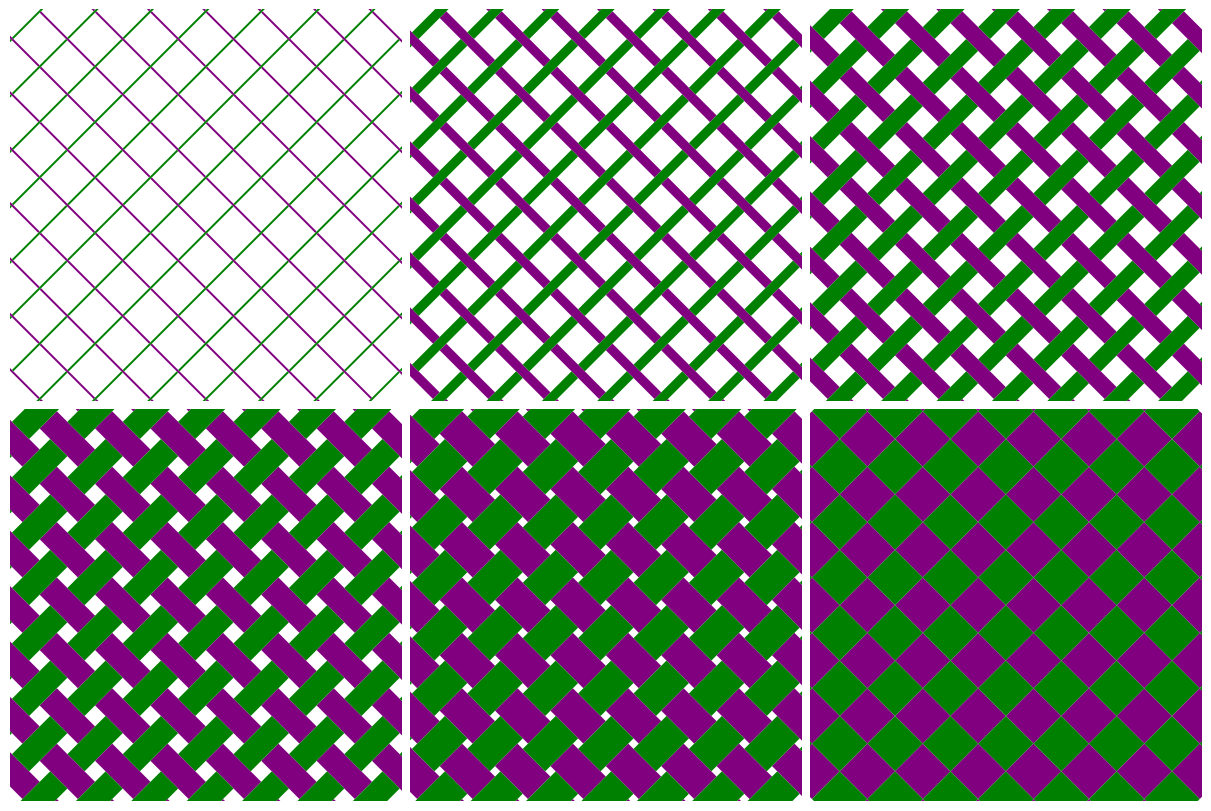

In [4]:
fig = pyplot.figure(
  figsize = (12, 8), 
  layout = "constrained"
)
weaves = [WeaveUnit(weave_type = "plain", aspect = asp).transform_rotate(45) 
          for asp in np.linspace(0.05, 1, 6, endpoint = True)]
for w, posn in zip(weaves, range(231, 237)):
  ax = fig.add_subplot(posn)
  w.plot(
    ax = ax, 
    r = 3, 
    r_alpha = 1, 
    cmap = ListedColormap(["purple", "green"]), 
    categorical = True, 
    show_ids = False, 
    show_prototile = False, 
    show_reg_prototile = False
  )
  ax.set_axis_off()
  ax.set_xlim(-5000, 5000)
  ax.set_ylim(-5000, 5000)

# pyplot.savefig("fig-01-weave-to-tiling.svg")

### Figure XX A tiled map of four variables

In [4]:
## This is a hangover from earlier versions, but has been used in Figure 2
d = gpd.read_file("data/ak-imd-sa2-2018.json").to_crs(2193)
rank_vars = d.columns[1:9]
rank_vars = list(rank_vars[1:]) + list(rank_vars[:1])
new_names = ["Employment", "Income", "Crime", "Housing", "Health", "Education", "Accessibility", "IMD"]
d = d[[v for v in d.columns if v in rank_vars or "geom" in v]]
d.rename({k: v for k, v in zip(rank_vars, new_names)}, axis = 1, inplace = True)
d = d[new_names + ["geometry"]]
# d.head()

In [9]:
t = TileUnit(
  # tiling_type = "square-slice", 
  tiling_type = "cairo", 
  n = 4, 
  offset = 1, 
  spacing = 450, 
  crs = d.crs
# ).transform_rotate(45).inset_prototile(12)
).transform_rotate(90).inset_prototile(12)
tiling = Tiling(t, d)
tm1 = tiling.get_tiled_map(
  join_on_prototiles = False,
  prioritise_tiles = True,
  debug = False,
)
tm1.legend = False
# tm1.use_ellipse = True
# tm1.legend_dx = -0.11
# tm1.legend_dy = -0.385
tm1.ids_to_map = list("abcd")
tm1.vars_to_map = ["Employment", "Income", "Crime", "Housing"]
tm1.colors_to_use = ["Reds", "Greens", "Greys", "Purples"]


### Figure 2 The tiling process

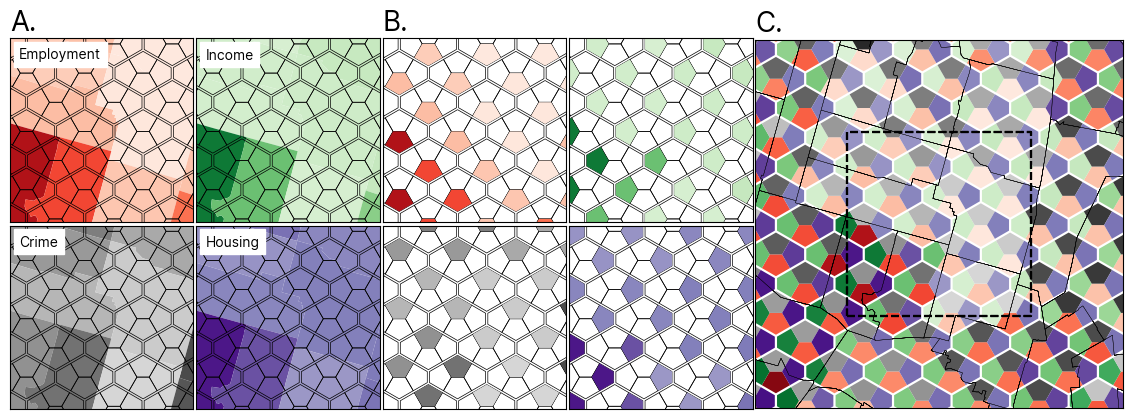

In [10]:
fig = pyplot.figure(
  layout = "constrained",
  figsize = (12, 4)
)

panels = fig.subplot_mosaic(
  "ABEFI;CDGHI",
  width_ratios = (1, 1, 1, 1, 2),
  height_ratios = (1, 1))

for panel in list("ABCDEFGHI"):
  ax = panels[panel]
  ax.set_xticks([])
  ax.set_yticks([])

columns = ["Employment", "Income", "Crime", "Housing"]
labels = [f"Attribute {x}" for x in range(1, 5)]
cmaps = ["Reds", "Greens", "Greys", "Purples"]
for panel, column, cmap, label in zip(list("ABCD"), columns, cmaps, labels):
  ax = panels[panel]
  d.plot(ax = ax, column = column, cmap = cmap, ec = "w", linewidth = 0)
  tm1.map.plot(ax = ax, fc = "#00000000", ec = "k", linewidth = 0.5)
  ax.set_xlim(1.756e6, 1.758e6)
  ax.set_ylim(5.914e6, 5.916e6)
  ax.annotate(text = column, xy = (0.05, 0.95), xycoords = "axes fraction",
              fontsize = 10, backgroundcolor = "w",
              horizontalalignment = "left", verticalalignment = "top")
  if panel == "A":
    ax.set_title("A.", x = 0.0, horizontalalignment = "left", fontsize = 20)

for panel, column, cmap, tile_id in zip(list("EFGH"), columns, cmaps, list("abcd")):
  ax = panels[panel]
  tm1.map.plot(ax = ax, fc = "#00000000", ec = "k", linewidth = 0.5)
  tm1.map[tm1.map.tile_id == tile_id].plot(ax = ax, column = column, cmap = cmap, linewidth = 0)
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_xlim(1.756e6, 1.758e6)
  ax.set_ylim(5.914e6, 5.916e6)
  if panel == "E":
    ax.set_title("B.", x = 0.0, horizontalalignment = "left", fontsize = 20)

ax = panels["I"]
for column, cmap, tile_id in zip(columns, cmaps, list("abcd")):
  tm1.map[tm1.map.tile_id == tile_id].plot(ax = ax, column = column, cmap = cmap)
  d.plot(ax = ax, fc = "#00000000", ec = "k", linewidth = 0.25)
  ax.plot([1.756e6, 1.758e6, 1.758e6, 1.756e6, 1.756e6],
          [5.914e6, 5.914e6, 5.916e6, 5.916e6, 5.914e6], color = "k", linestyle = "dashed")
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_xlim(1.755e6, 1.759e6)
  ax.set_ylim(5.913e6, 5.917e6)
  ax.set_title("C.", x = 0.0, horizontalalignment = "left", fontsize = 20)

fig.get_layout_engine().set(wspace = 0.01, hspace = 0.01, w_pad = 0.0, h_pad = 0.0)
fig.get_layout_engine()._compress = True
# pyplot.savefig("fig-02-tiling-process.svg")

### Figure 3 Hedrality and isohedrality

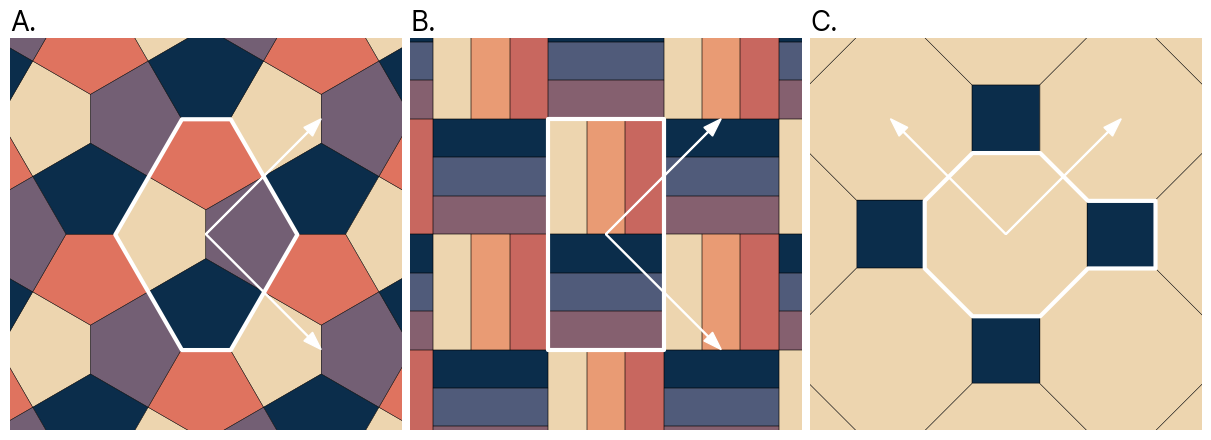

In [6]:
t488 = TileUnit(tiling_type = "archi", code = "4.8.8", spacing = 1000).transform_rotate(-135)
cairo = TileUnit(tiling_type = "cairo", spacing = 1000)

cheese = TileUnit(base_shape = TileShape.RECTANGLE)
b33 = WeaveUnit(weave_type = "basket", n = 3, strands = "abc|def", spacing = 1000 / np.sqrt(2) / 3)
tiles = list(b33.tiles.geometry)[0:12:2]
cheese.tiles = gpd.GeoDataFrame(
  data = {"tile_id": list("abcdef")},
  geometry = gpd.GeoSeries([affine.translate(t, -500 / np.sqrt(2), 0) for t in tiles]),
  crs = cheese.crs
)
cheese.setup_vectors((1000 / np.sqrt(2), 1000 / np.sqrt(2)), (1000 / np.sqrt(2), -1000 / np.sqrt(2)))
cheese.prototile = cheese.get_prototile_from_vectors()
cheese.regularised_prototile = gpd.GeoDataFrame(geometry = gpd.GeoSeries(cheese.tiles.geometry.union_all()), crs = cheese.crs)
cheese = cheese

fig, axes = pyplot.subplots(1, 3, figsize = (12, 4.3), layout = "constrained")
for ax, t, ttl in zip(axes, [cairo, cheese, t488], list("ABC")):
  t.plot(
    ax = ax, 
    r = 3, 
    show_prototile = False, 
    show_reg_prototile = False,
    show_ids = False, 
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = ax, fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = ax, fc = "#00000000", ec = "w", lw = 3)
  for v in t.get_vectors()[:2]:
    ax.arrow(0, 0, v[0], v[1], length_includes_head = True, width = 6, head_width = 75, color = "w")
  ax.set_axis_off()
  ax.set_xlim(-1200, 1200)
  ax.set_ylim(-1200, 1200)
  ax.set_title(f"{ttl}.", x = 0.0, horizontalalignment = "left", fontsize = 20)

# pyplot.savefig("fig-03-hedrality.svg")

### Figure 4 Symmetry

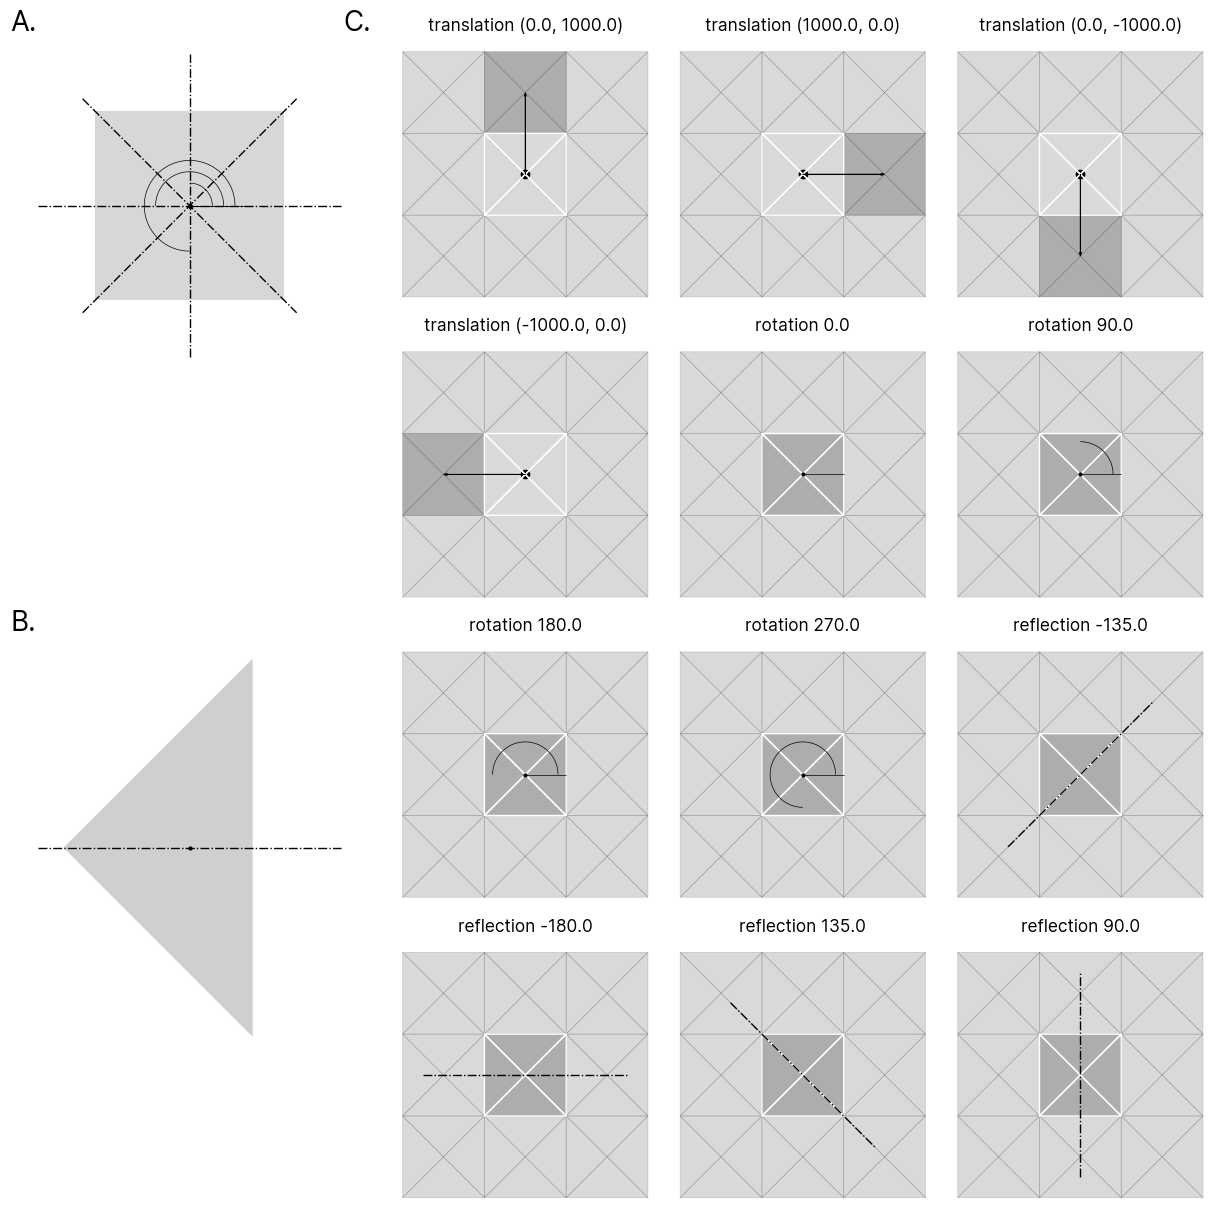

In [12]:
# from weavingspace import Shape_Matcher
from weavingspace import Symmetries

t = TileUnit(tiling_type = "square-slice", n = 4, offset = 0, spacing = 1000)
topo = Topology(t)
trs = topo.tile_matching_transforms

n = len(trs)
nr = int(np.ceil(np.sqrt(n)))
nc = int(np.ceil(n / nr))

fig = pyplot.figure(
  layout = "constrained",
  figsize = (12, 12)
)
# left, mid, right = fig.subfigures(
#   nrows = 1, ncols = 3,
#   width_ratios = (10, 1, 25)
# )
panels = fig.subplot_mosaic(
  """
  ACDEF
  ACGHI
  BCJKL
  BCMNO
  """,
  width_ratios = (10, 1, 8.33, 8.33, 8.33),
  height_ratios = (9, 9, 9, 9)
)
for pid, panel in panels.items():
  panel.set_axis_off()
  panel.set_anchor("NW")
  if pid in "ABC":
    panel.set_title(f"{pid}.", ha = "center", fontsize = 20, x = 0.0)

sq = tiling_utils.get_regular_polygon(500, 4)
s_sq = Symmetries(sq)
# ax = axes_left["A"]
ax = panels["A"]
gpd.GeoSeries([sq]).plot(ax = ax, fc = "#00000028")
for i, s_sq in enumerate(s_sq.symmetries):
  s_sq.draw(ax, radius = 30 * (i + 1),
            mirror_length = 800, w = 5,
            add_title = False)

p = t.tiles.geometry[0]
s = Symmetries(p)
# ax = axes_left["B"]
ax = panels["B"]
gpd.GeoSeries([p]).plot(ax = ax, fc = "#00000030")
for i, s in enumerate(s.symmetries):
  s.draw(ax, radius = 10 * (i + 1), 
         mirror_length = 800, w = 5, 
         add_title = False)

# for tr, ax in zip(trs.values(), axes_right.values()):
for tr, pid in zip(trs.values(), list("DEFGHIJKLMNO")):
  ax = panels[pid]
  topo._plot_tiling_symmetry(
    transform = tr, ax = ax, mirror_length = 2500, 
    radius = 400, c = geom.Point(0, 0))

fig.get_layout_engine().set(wspace = 0.001, hspace = 0.001, w_pad = 0.0, h_pad = 0.0)

# pyplot.savefig("fig-04-tiling-symmetries.svg")

### Figure 5 Topology

CAUTION: new Topology will probably not be correctly labelled. To build a correct Topology, extract the tileable attribute and rebuild Topology from that.


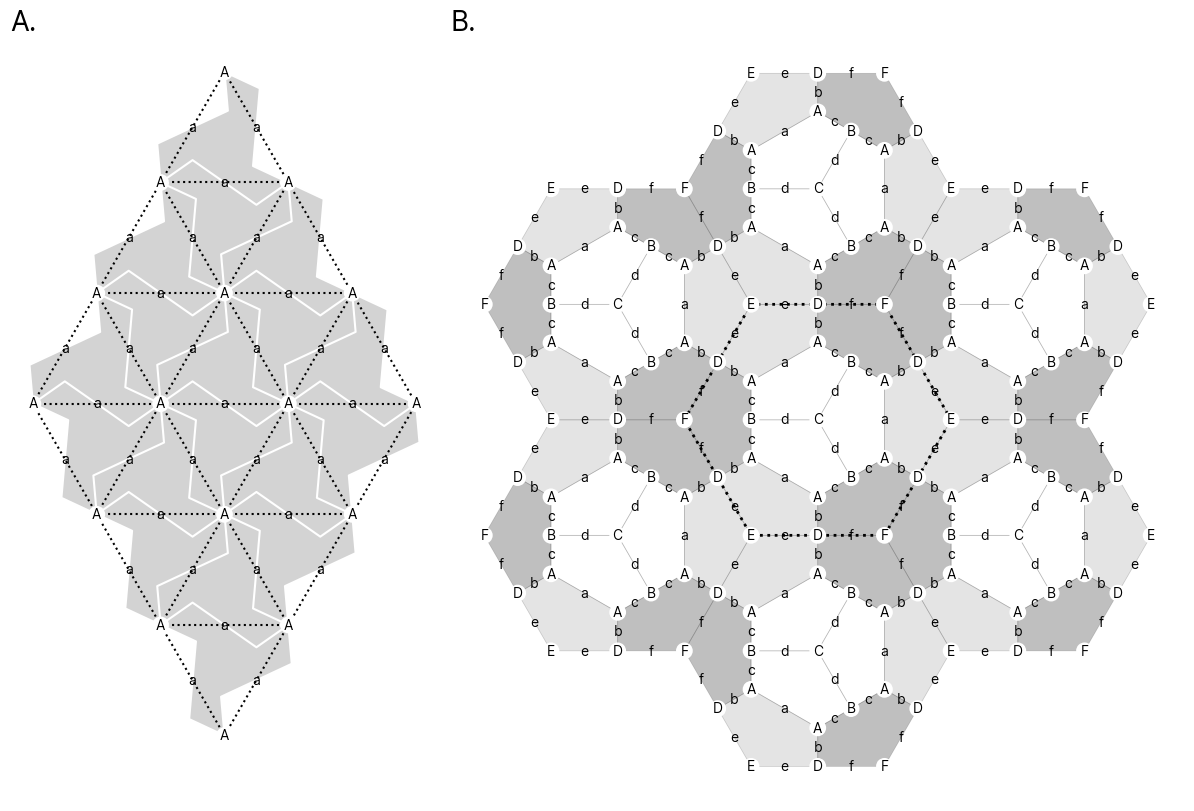

In [13]:
fig, axes = pyplot.subplots(
  nrows = 1, ncols = 2,
  width_ratios = (4, 7),
  figsize = (12, 8),
  layout = "constrained",
)

t1 = TileUnit(base_shape = TileShape.TRIANGLE)
topo1 = Topology(t1)
topo12 = topo1.transform_geometry(True, True, "a", "zigzag_edge", n = 2, h = 0.35, smoothness = 0)
ax = axes[0]
topo12.tileable.get_local_patch(r = 1, include_0 = True).plot(ax = ax, fc = "lightgrey")
gpd.GeoSeries([geom.LineString([c.point for c in e.corners]) for e in topo12.edges.values()]).plot(ax = ax, ec = "w")
topo12._get_edge_geoms().plot(ax = ax, ec = "k", ls = ":", fc = "#00000000")
topo12._plot_edges(ax = ax, show_edges = False, show_edge_labels = True, dist = 0)
for v in topo12.points.values():
  ax.annotate(v.label, xy = (v.point.x, v.point.y), color = "k",
              ha = "center", va = "center", bbox=dict(boxstyle="circle,pad=0.1", fc="w", lw=0))

t2 = TileUnit(tiling_type = "hex-dissect", n = 9, offset = 1, offset_angle = 30)
topo2 = Topology(t2)
ax = axes[1]
topo2._plot_tiles(ax = ax)
topo2._plot_edges(ax = ax, show_edges = False, show_edge_labels = True, dist = 0)
for v in topo2.points.values():
  ax.annotate(v.label, xy = (v.point.x, v.point.y), color = "k", ha = "center",
              va = "center", bbox=dict(boxstyle="circle,pad=0.1", fc="w", lw=0))
t2.prototile.geometry.plot(ax = ax, ec = "k", ls = ":", lw = 2, fc = "#00000000")

for ax, lbl in zip(axes, "AB"):
  ax.set_axis_off()
  ax.set_title(f"{lbl}.", x = 0.0, horizontalalignment = "left", fontsize = 20)
  ax.set_anchor("NW")

# pyplot.savefig("fig-05-topology.svg")

### Figure 6 Sample weave patterns

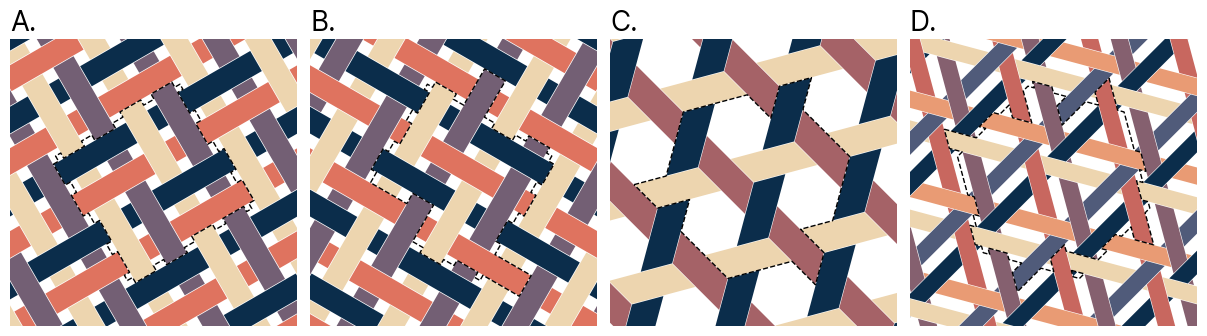

In [17]:
# w1 = WeaveUnit(weave_type = "plain", n = 1, spacing = 100, crs = 3857, aspect = 2/3)
w2 = WeaveUnit(weave_type = "basket", n = 2, strands = "ac|bd", spacing = 100, crs = 3857, aspect = 2/3).transform_rotate(30).inset_tiles(1)
w3 = WeaveUnit(weave_type = "twill", n = 2, strands = "ac|bd", spacing = 100, crs = 3857, aspect = 2/3).transform_rotate(-30).inset_tiles(1)
w4 = WeaveUnit(weave_type = "cube", strands = "a--|b--|c--", spacing = 100, crs = 3857, aspect = 1).transform_rotate(15).inset_tiles(1)
w5 = WeaveUnit(weave_type = "cube", strands = "ab-|c-d|-ef", spacing = 100, crs = 3857, aspect = 3/5).transform_rotate(-15).inset_tiles(1)

fig, axes = pyplot.subplots(1, 4, figsize = (12, 3.25), layout = "constrained")

for w, ax, wdth, ttl in zip([w2, w3, w4, w5], axes, [400, 400, 500, 500], [f"{c}." for c in "ABCD"]):
  w.plot(
    ax = ax, r = 2, 
    show_prototile = False, 
    show_reg_prototile = False, 
    show_ids = False, 
    r_alpha = 1, 
    cmap = get_cols_2(w, "cmc.lipari_r", min = 20, max = 235),
  )
  w.regularised_prototile.geometry.plot(ax = ax, ec = "k", lw = 1, ls = "--", fc = "#00000000")
  ax.set_axis_off()
  ax.set_xlim(-wdth, wdth)
  ax.set_ylim(-wdth, wdth)
  ax.set_title(ttl, x = 0.0, horizontalalignment = "left", fontsize = 20)

# pyplot.savefig("fig-06-some-weave-pattern-samples.svg")

### Figure 7 Archimedean tilings

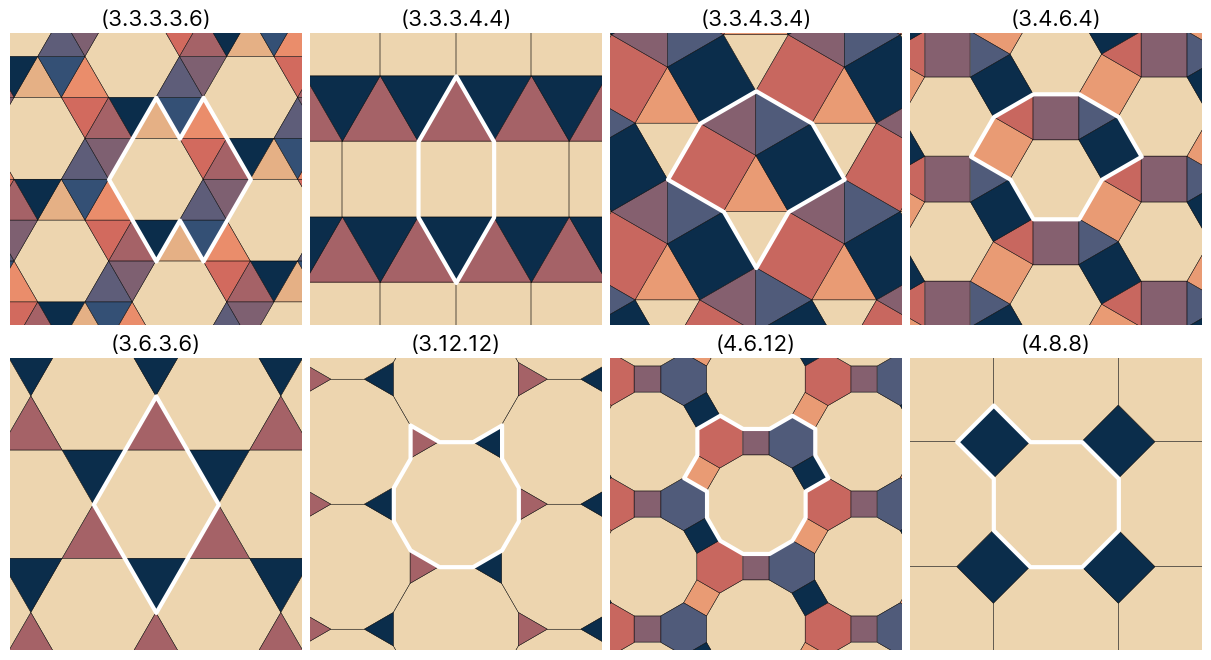

In [ ]:
codes = ["3.3.3.3.6", "3.3.3.4.4", "3.3.4.3.4", "3.4.6.4", "3.6.3.6", "3.12.12", "4.6.12", "4.8.8"]
fig, axes = pyplot.subplots(
  nrows = 2, ncols = 4,
  figsize = (12, 6.5),
  layout = "constrained",
)
for i, code in enumerate(codes):
  r, c = i // 4, i % 4
  t = TileUnit(tiling_type = "archi", code = code, spacing = 600, crs = d.crs)
  t.plot(
    ax = axes[r, c],
    r = 3, 
    show_ids = False, 
    show_prototile = False, 
    show_reg_prototile = False,
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = axes[r, c], fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = axes[r, c], fc = "#00000000", ec = "w", lw = 3)
  axes[r, c].set_axis_off()
  axes[r, c].set_xlim(-700, 700)
  axes[r, c].set_ylim(-700, 700)
  axes[r, c].set_title(f"({code})", fontsize = 16)

# pyplot.savefig("fig-07-archimedean.svg")

### Figure 8 _k_-regular tilings (Chavey)

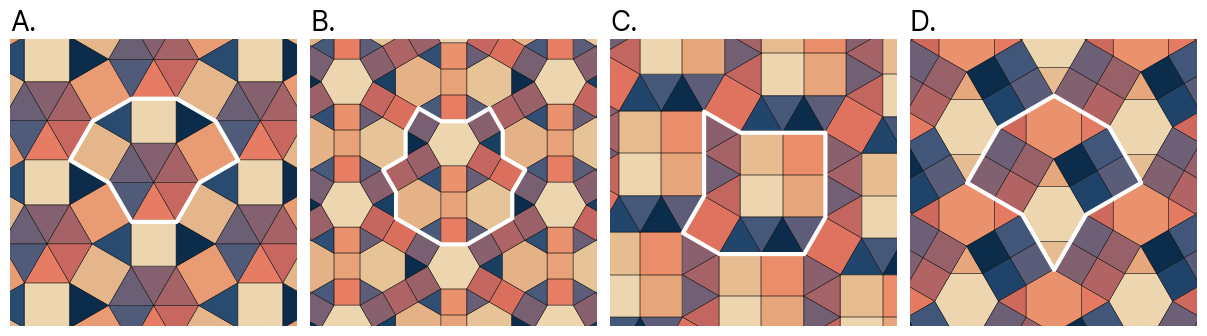

In [103]:
codes = list("ECAB")
fig, axes = pyplot.subplots(
  nrows = 1, ncols = 4,
  figsize = (12, 3.25),
  layout = "constrained",
)
for i, (code, ttl) in enumerate(zip(codes, "ABCD")):
  t = TileUnit(tiling_type = "chavey", code = code, spacing = 600, crs = d.crs)
  t.plot(
    ax = axes[i],
    r = 3, 
    show_ids = False, 
    show_prototile = False, 
    show_reg_prototile = False, 
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = axes[i], fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = axes[i], fc = "#00000000", ec = "w", lw = 3)
  axes[i].set_axis_off()
  axes[i].set_xlim(-700, 700)
  axes[i].set_ylim(-700, 700)
  axes[i].set_title(f"{ttl}.", x = 0.0, horizontalalignment = "left", fontsize = 20)

# pyplot.savefig("fig-08-chavey.svg")

### Figure 9 Laves tilings

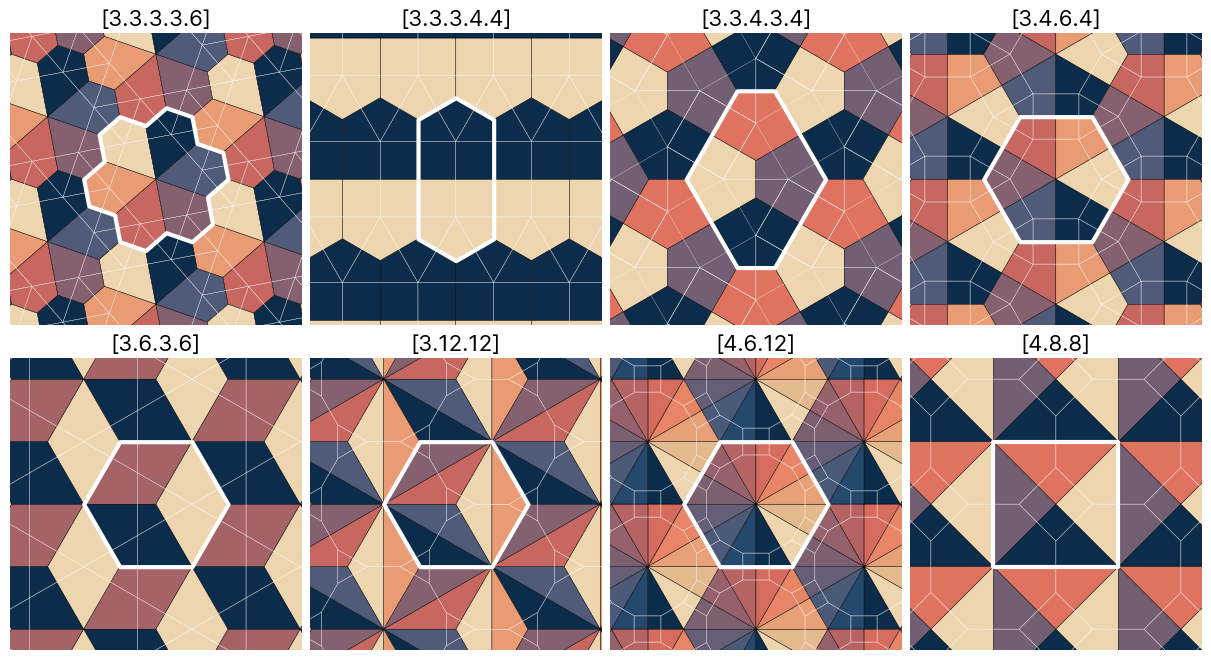

In [ ]:
codes = ["3.3.3.3.6", "3.3.3.4.4", "3.3.4.3.4", "3.4.6.4", "3.6.3.6", "3.12.12", "4.6.12", "4.8.8"]
fig, axes = pyplot.subplots(
  nrows = 2, ncols = 4,
  figsize = (12, 6.5),
  layout = "constrained",
)
for i, code in enumerate(codes):
  r, c = i // 4, i % 4
  t = TileUnit(tiling_type = "laves", code = code, spacing = 600, crs = d.crs)
  t.plot(
    ax = axes[r, c],
    r = 4 if i == 1 else 3, 
    show_ids = False, 
    show_prototile= False,
    show_reg_prototile = False,
    reg_prototile_edgecolour = "w",
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = axes[r, c], fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = axes[r, c], fc = "#00000000", ec = "w", lw = 3)
  dtu = tiling_utils.get_dual_tile_unit(t)
  dt = copy.deepcopy(t)
  dt.tiles = dtu
  dt.get_local_patch(r = 3, include_0 = True).plot(ax = axes[r, c], fc = "#00000000", ec = "w", lw = 0.2)
  axes[r, c].set_axis_off()
  axes[r, c].set_xlim(-700, 700)
  axes[r, c].set_ylim(-700, 700)
  axes[r, c].set_title(f"[{code}]", fontsize = 16)

# pyplot.savefig("fig-09-laves.svg")

### Figure 10 Colourings

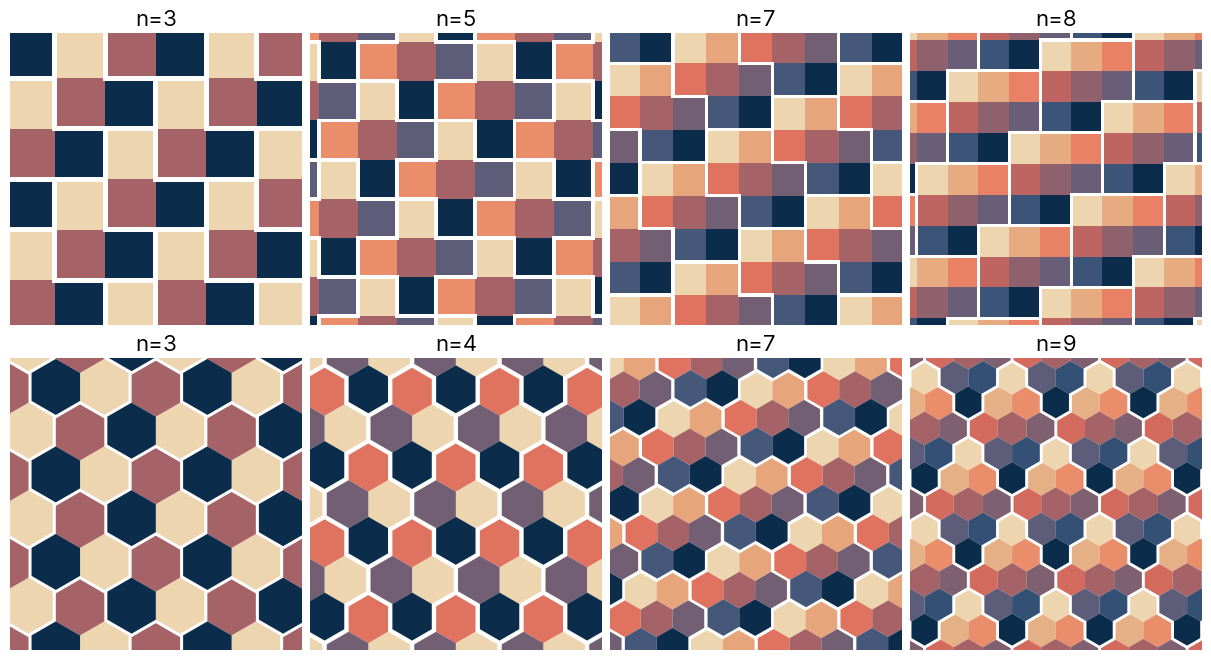

In [ ]:
types = ["square-col"] * 4 + ["hex-col"] * 4
ns = [3, 5, 7, 8, 3, 4, 7, 9]
fig, axes = pyplot.subplots(
  nrows = 2, ncols = 4,
  figsize = (12, 6.5),
  layout = "constrained",
)
for i, (ttype, n) in enumerate(zip(types, ns)):
  r, c = i // 4, i % 4
  if i in (0, 1, 2, 3, 5, 7):
    t = TileUnit(tiling_type = ttype, n = n, 
                 spacing = 600, crs = d.crs).inset_prototile(t.spacing * 0.05 / np.sqrt(n))
  else:
    t = TileUnit(tiling_type = ttype, n = n, 
                spacing = 600, crs = d.crs).transform_scale(0.96, 0.96, independent_of_tiling = True)
  t.plot(
    ax = axes[r, c],
    r = 3, 
    show_ids = False, 
    show_prototile= False, 
    show_reg_prototile = False,
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  # t.get_local_patch(r = 3, include_0 = True).plot(ax = axes[r, c], fc = "#00000000", ec = "k", lw = 0.25)
  axes[r, c].set_axis_off()
  axes[r, c].set_xlim(-1000, 1000)
  axes[r, c].set_ylim(-1000, 1000)
  axes[r, c].set_title(f"{n=}", fontsize = 16)

# pyplot.savefig("fig-10-colourings.svg")

### Figure 11 Slices, dissections, stripes, and grids

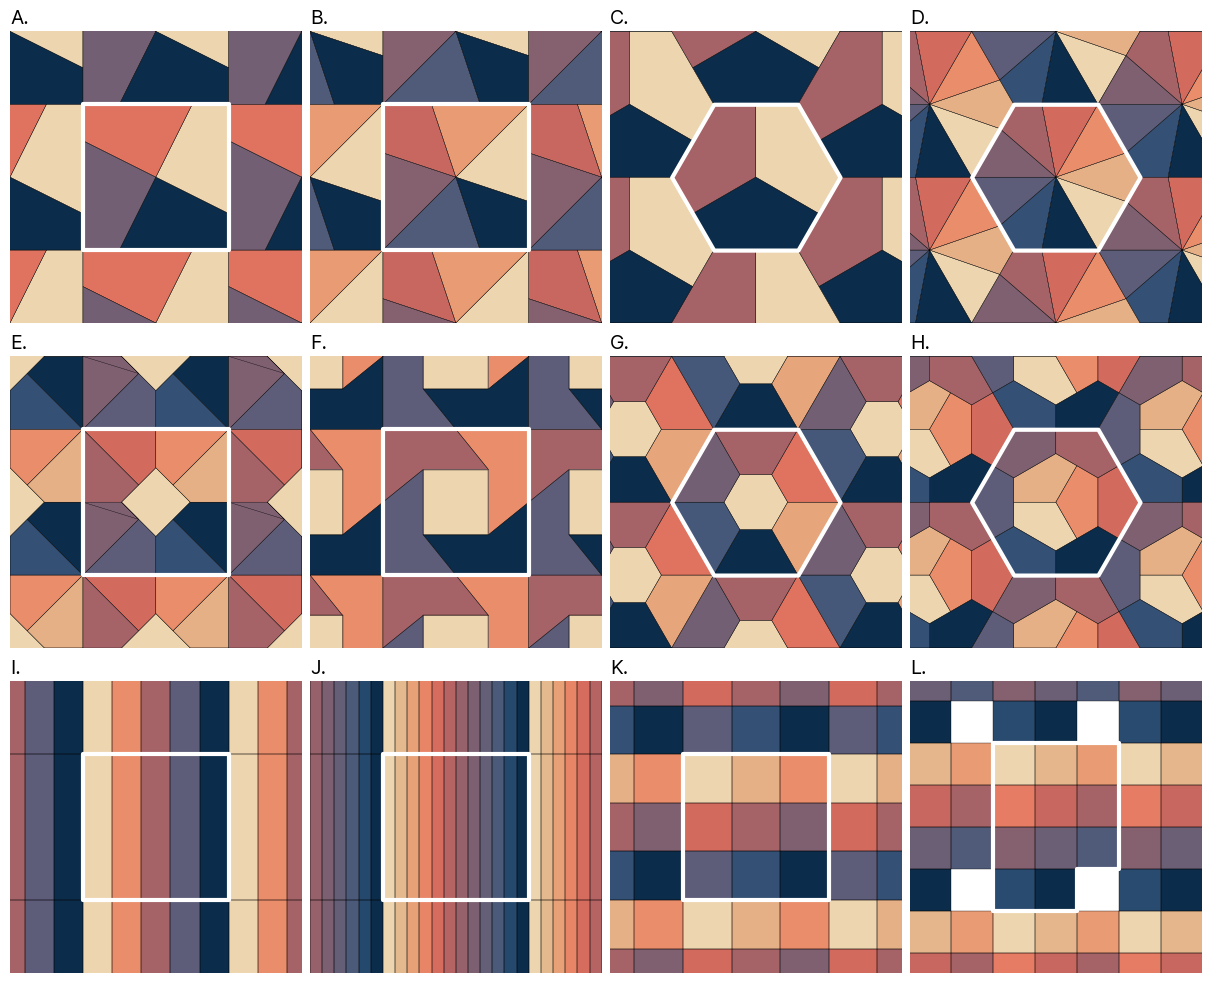

In [106]:
tile_specs = dict(
  A = dict(tiling_type = "square-slice", n = 4, offset = 0.5),
  B = dict(tiling_type = "square-slice", n = 6, offset = 1),
  C = dict(tiling_type = "hex-slice", n = 3, offset = 1),
  D = dict(tiling_type = "hex-slice", n = 9, offset = 0),
  E = dict(tiling_type = "square-dissection", n = 9, offset = 1, offset_angle = 45),
  F = dict(tiling_type = "square-dissection", n = 5, offset = 1, offset_angle = 0),
  G = dict(tiling_type = "hex-dissection", n = 7, offset = 0, offset_angle = 0),
  H = dict(tiling_type = "hex-dissection", n = 9, offset = 1, offset_angle = 30),
  I = dict(tiling_type = "stripe", n = 5),
  J = dict(tiling_type = "stripe", n = 12),
  K = dict(tiling_type = "grid", n = 9, nrows = 3, ncols = 3),
  L = dict(tiling_type = "grid", n = 11, nrows = 4, ncols = 3)
)
types = ["square-slice"] * 2 + \
        ["hex-slice"] * 2 + \
        ["square-dissection"] * 2 + \
        ["hex-dissection"] * 2 + \
        ["stripe"] * 2 + \
        ["grid"] * 2
ns = [6, 8, 3, 9, 5, 9, 7, 9, 5, 25, 16, 25]
offsets = [1] * 8 + [None] * 4
offset_angles = [None] * 4 + [45, 45, 30, 30] + [None] * 4

fig = pyplot.figure(
  figsize = (12, 9.75),
  layout = "constrained"
)
panels = fig.subplot_mosaic(
  "ABCD;EFGH;IJKL"
)

for panel, tile_spec in tile_specs.items():
  t = TileUnit(**tile_spec)
  ax = panels[panel]
  t.plot(
    ax = ax,
    r = 3, 
    show_ids = False, 
    show_prototile = False, 
    show_reg_prototile = False, 
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = ax, fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = ax, fc = "#00000000", ec = "w", lw = 3)
  ax.set_axis_off()
  ax.set_xlim(-1000, 1000)
  ax.set_ylim(-1000, 1000)
  ax.set_title(f"{panel}.", x = 0.0, horizontalalignment = "left", fontsize = 14)

# pyplot.savefig("fig-11-slices-dissections-stripes-grids.svg")

### Figure 12 Affine transformations and edge transformations

CAUTION: new Topology will probably not be correctly labelled. To build a correct Topology, extract the tileable attribute and rebuild Topology from that.
CAUTION: new Topology will probably not be correctly labelled. To build a correct Topology, extract the tileable attribute and rebuild Topology from that.
CAUTION: new Topology will probably not be correctly labelled. To build a correct Topology, extract the tileable attribute and rebuild Topology from that.
CAUTION: new Topology will probably not be correctly labelled. To build a correct Topology, extract the tileable attribute and rebuild Topology from that.
CAUTION: new Topology will probably not be correctly labelled. To build a correct Topology, extract the tileable attribute and rebuild Topology from that.


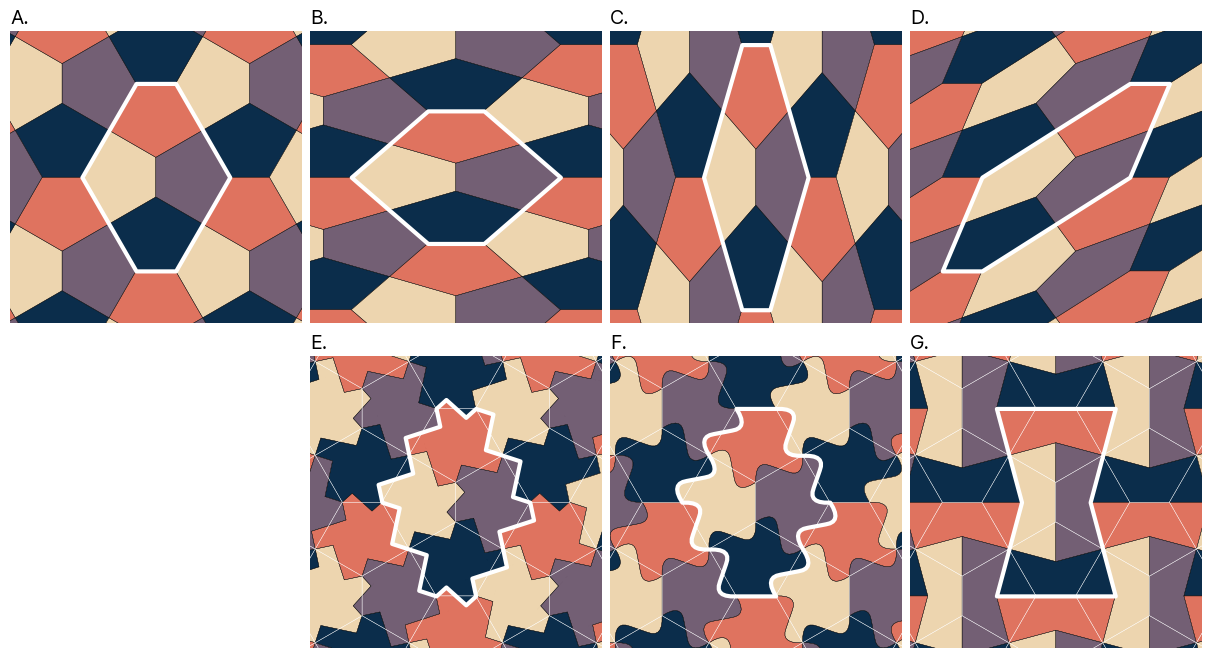

In [ ]:
t0 = TileUnit(tiling_type = "cairo", spacing = 100)
t1 = t0.transform_scale(np.sqrt(2), 1 / np.sqrt(2))
t2 = t0.transform_scale(1 / np.sqrt(2), np.sqrt(2))
t3 = t0.transform_skew(45)
# t0 = TileUnit(tiling_type = "square-col", n = 4, spacing = 100)
topo0 = Topology(t0)
topo4 = topo0 \
  .transform_geometry(True, False, "b", "zigzag_edge", n = 2, h = 0.45, smoothness = 0) \
  .transform_geometry(False, True, "a", "zigzag_edge", n = 2, h = 0.45, smoothness = 0)
t4 = topo4.tileable
t4._setup_regularised_prototile(True)

topo5 = topo0 \
  .transform_geometry(True, True, "a", "zigzag_edge", n = 2, h = 0.45, smoothness = 7)
t5 = topo5.tileable
t5._setup_regularised_prototile(True)

topo0x = Topology(t0, ignore_tile_ids = False)
topo6 = topo0x \
  .transform_geometry(True, False, "d", "scale_edge", sf = 3) \
  .transform_geometry(False, True, "h", "scale_edge", sf = 3)
t6 = topo6.tileable
t6._setup_regularised_prototile(True)

fig = pyplot.figure(figsize = (12, 6.5), layout = "constrained")
panels = fig.subplot_mosaic(
  """
  ABCD
  .EFG
  """,
  width_ratios = (1, 1, 1, 1),
  height_ratios = (1, 1)
)

for t, (ttl, ax) in zip([t0, t1, t2, t3, t4, t5, t6], panels.items()):
  t.plot(
    ax = ax,
    r = 3, 
    show_ids = False, 
    show_prototile = False, 
    show_reg_prototile = False, 
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = ax, fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = ax, fc = "#00000000", ec = "w", lw = 3)
  if ttl > "D":
    t0.get_local_patch(r = 3, include_0 = True).plot(ax = ax, fc = "#00000000", ec = "w", lw = 0.25)
  ax.set_axis_off()
  ax.set_xlim(-110, 110)
  ax.set_ylim(-110, 110)
  ax.set_title(f"{ttl}.", fontsize = 14, x = 0.0, ha = "left")

# pyplot.savefig("fig-12-affine-and-edge-transforms.svg")

### Figure 13 Dual tilings and more

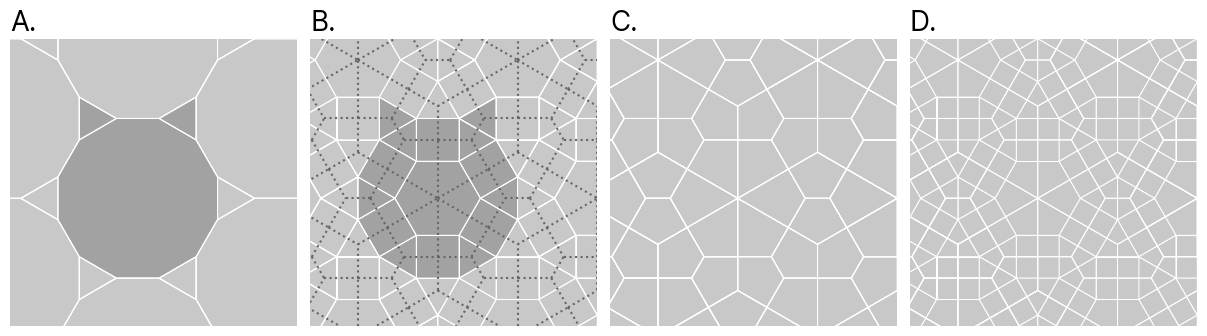

In [21]:
import copy

t0 = TileUnit(tiling_type = "archi", code = "3.12.12")
t0_tiles = t0.get_local_patch(r = 2, include_0 = True)
t1 = TileUnit(tiling_type = "chavey", code = "h")
t2 = copy.deepcopy(t1)
t2.tiles = tiling_utils.get_dual_tile_unit(t1)
t2._setup_regularised_prototile()
topo2 = Topology(t2)
t3 = t1.get_local_patch(r = 2, include_0 = True)
t4 = t2.get_local_patch(r = 2, include_0 = True)
t5 = t3.overlay(t4)
t5.geometry = gpd.GeoSeries([tiling_utils.get_clean_polygon(p) for p in t5.geometry])

fig, axes = pyplot.subplots(
  nrows = 1, ncols = 4,
  layout = "constrained",
  figsize = (12, 3.25)
)
t0_tiles.plot(ax = axes[0], fc = "#c8c8c8", ec = "w", lw = 0.75)
t0.regularised_prototile.geometry.plot(ax = axes[0], fc = "#00000030", lw = 0.0)
t0_tiles.plot(ax = axes[0], fc = "#00000000", ec = "w", lw = 0.75)
t3.plot(ax = axes[1], fc = "#c8c8c8")
t0.regularised_prototile.geometry.plot(ax = axes[1], fc = "#00000030", lw = 0.0)
# use topology derived edge geometries to avoid double plotting of
# edges using dash-dot style - which results in confusion
topo2._get_edge_geoms().plot(ax = axes[1], ec = "#666666", linestyle = ":")
t3.plot(ax = axes[1], fc = "#00000000", ec = "w", lw = 0.75)
t4.plot(ax = axes[2], fc = "#c8c8c8", ec = "w", lw = 0.75)
t4.plot(ax = axes[2], fc = "#00000000", ec = "w", lw = 0.75)
t3.plot(ax = axes[3], fc = "#c8c8c8", ec = "w", lw = 0.75)
t4.plot(ax = axes[3], fc = "#00000000", ec = "w", lw = 0.75)
for ax, lbl in zip(axes, "ABCD"):
  # Note: the topology derived edge geoms from the dual don't stretch far!
  ax.set_xlim(-800, 1000)
  ax.set_ylim(-800, 1000)
  ax.set_axis_off()
  ax.set_title(f"{lbl}.", x = 0.0, horizontalalignment = "left", fontsize = 20)

# pyplot.savefig("fig-13-morphing-tilings.svg")

### Figure 14 Reaggregation

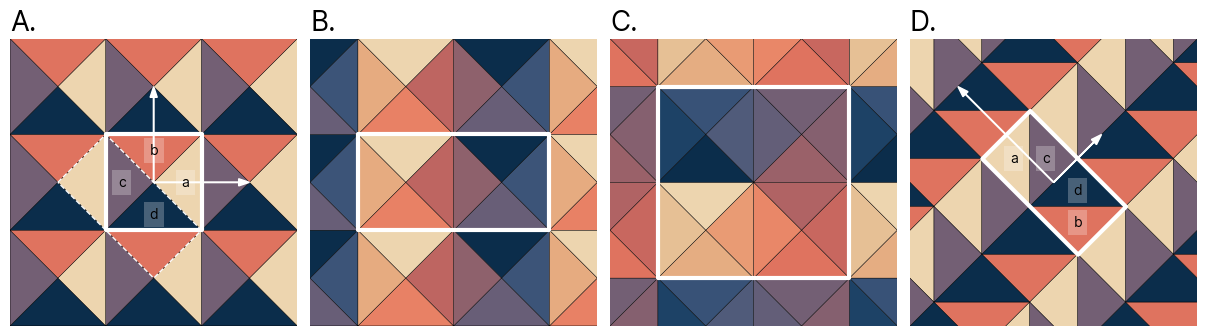

In [ ]:
t0 = TileUnit(tiling_type = "square-slice", n = 4, offset = 0)

t1 = copy.deepcopy(t0)
t1_shapes = [x for x in t1.tiles.geometry]
t1_shapes[0] = affine.translate(t1_shapes[0], -750, 250)
t1_shapes[1] = affine.translate(t1_shapes[1], 250, -750)
t1_shapes[2] = affine.translate(t1_shapes[2], 250, 250)
t1_shapes[3] = affine.translate(t1_shapes[3], 250, 250)
t1.tiles.geometry = gpd.GeoSeries(t1_shapes)
t1.prototile = gpd.GeoDataFrame(geometry = gpd.GeoSeries([t1.tiles.union_all(grid_size = 0.1).simplify(0.1)]))
t1._set_vectors_from_prototile()
t1._setup_regularised_prototile(True)

t2 = copy.deepcopy(t0)
t2_shapes_a = [affine.translate(x, -500, 0) for x in t2.tiles.geometry]
t2_shapes_b = [affine.translate(x,  500, 0) for x in t2.tiles.geometry]
t2.tiles = gpd.GeoDataFrame(
  geometry = gpd.GeoSeries(t2_shapes_a + t2_shapes_b),
  data = {"tile_id": list("dabcghef")})
t2.prototile = gpd.GeoDataFrame(geometry = gpd.GeoSeries([t2.tiles.union_all(grid_size = 0.1).simplify(0.1)]))
t2._set_vectors_from_prototile()
t2._setup_regularised_prototile(True)

t3 = copy.deepcopy(t0)
t3_shapes_a = [affine.translate(x, -500, -500) for x in t3.tiles.geometry]
t3_shapes_b = [affine.translate(x,  500, -500) for x in t3.tiles.geometry]
t3_shapes_c = [affine.translate(x,  500,  500) for x in t3.tiles.geometry]
t3_shapes_d = [affine.translate(x, -500,  500) for x in t3.tiles.geometry]
t3.tiles = gpd.GeoDataFrame(
  geometry = gpd.GeoSeries(t3_shapes_a + t3_shapes_b + t3_shapes_c + t3_shapes_d),
  data = {"tile_id": list("dabcghefjklimnop")})
t3.prototile = gpd.GeoDataFrame(geometry = gpd.GeoSeries([t3.tiles.union_all(grid_size = 0.2).simplify(0.1)]))
t3._set_vectors_from_prototile()
t3._setup_regularised_prototile(True)

fig, axes = pyplot.subplots(
  nrows = 1, ncols = 4,
  layout = "constrained",
  figsize = (12, 3.25)
)
for t, ax, lbl in zip([t0, t2, t3, t1], axes, "ABCD"):
  t.plot(
    ax = ax,
    r = 3,
    show_ids = lbl in ["A", "D"],
    show_prototile = False, 
    show_reg_prototile = False, 
    r_alpha = 1, 
    cmap = get_cols_2(t, "cmc.lipari_r", min = 20, max = 235),
  )
  t.get_local_patch(r = 3, include_0 = True).plot(ax = ax, fc = "#00000000", ec = "k", lw = 0.25)
  t.regularised_prototile.plot(ax = ax, fc = "#00000000", ec = "w", lw = 3)
  if lbl in ["A", "D"]:
    for v in t.get_vectors()[:2]:
      ax.arrow(0, 0, v[0], v[1], length_includes_head = True, width = 6, head_width = 75, color = "w")
  if lbl == "A":
    pt = gpd.GeoDataFrame(geometry = t1.prototile.geometry.translate(-250, -250))
    pt.plot(ax = ax, fc = "#00000000", ec = "w", ls = "dashed")
  ax.set_xlim(-1500, 1500)
  ax.set_ylim(-1500, 1500)
  ax.set_axis_off()
  ax.set_title(f"{lbl}.", x = 0.0, horizontalalignment = "left", fontsize = 20)

# pyplot.savefig("fig-14-reaggregation.svg")

### Figure 15 Twelve hex slice drought index

In [23]:
pdsi = gpd.read_file("data/pdsi-2025.gpkg")
t1 = TileUnit(tiling_type = "hex-slice", n = 12, offset = 0, spacing = 1e5, crs = pdsi.crs).transform_scale(-1, 1).transform_rotate(-150).inset_prototile(1e3)
# t = TileUnit(tiling_type = "stripe", n = 12, spacing = 1.2e5, crs = pdsi.crs).transform_scale(1, 0.4).inset_prototile(2e3)
# t = WeaveUnit(weave_type = "basket", n = 6, strands = "abcdef|ghijkl", aspect = 0.8, spacing = 2e4, crs = pdsi.crs).transform_rotate(45)
# t.plot(r = 1)
tiling1 = Tiling(t1, pdsi)

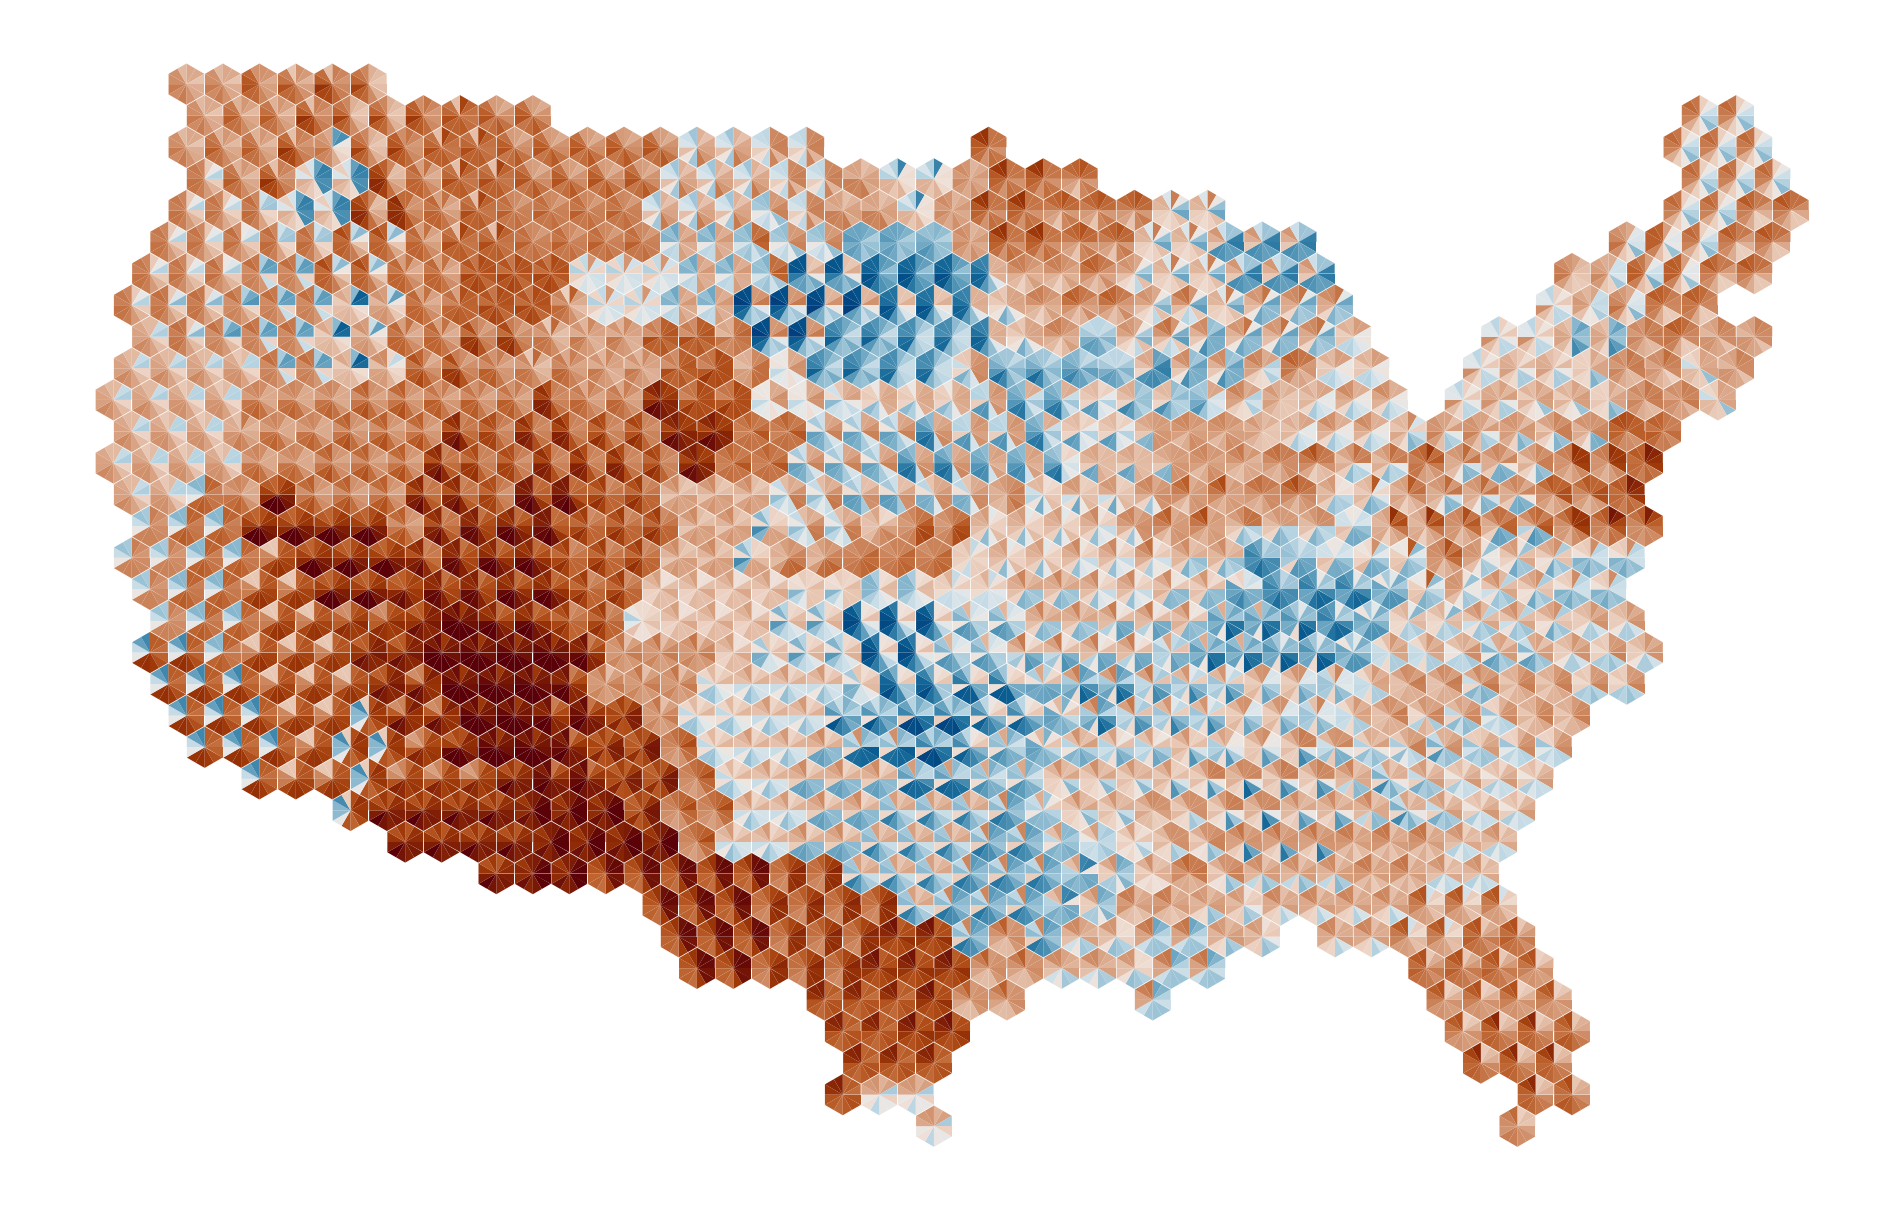

In [24]:
fig = pyplot.figure(figsize = (20, 12), layout = "constrained")
ax = fig.add_subplot(111)
ax.set_axis_off()
tm1 = tiling1.get_tiled_map(
  join_on_prototiles = True, # note using true here
  retain_tileables = True,
  prioritise_tiles = True,
  debug = False,
)
# want to use one of the Crameri schemes which isn't currently supported in weavingspace
for tile_id, column in zip(list("abcdefghijkl"), list(calendar.month_name)[1:]):
  tm1.map[tm1.map.tile_id == tile_id].plot(ax = ax, column = column, cmap = "cmc.vik_r", scheme = None, vmin = -6, vmax = 6)

# pyplot.savefig("fig-15-pdsi-2025.svg")

### Figure 16 NYC race

In [22]:
nyc = gpd.read_file("data/nyc-acs-2024-race.gpkg").to_crs(3857)
manhattan = gpd.GeoDataFrame(geometry = gpd.GeoSeries([nyc.geometry.union_all()]), crs = nyc.crs)
t2 = TileUnit(tiling_type = "square-slice", n = 4, offset = 0, spacing = 600, crs = nyc.crs).transform_scale(-1, 1)
t2 = TileUnit(tiling_type = "cairo", spacing = 600, crs = nyc.crs).inset_prototile(10)
t3 = WeaveUnit(weave_type = "basket", n = 2, strands = "ab|cd", spacing = 250, aspect = 2/3, crs = nyc.crs).transform_rotate(60)
tiling2 = Tiling(t2, nyc)
tiling3 = Tiling(t3, nyc)

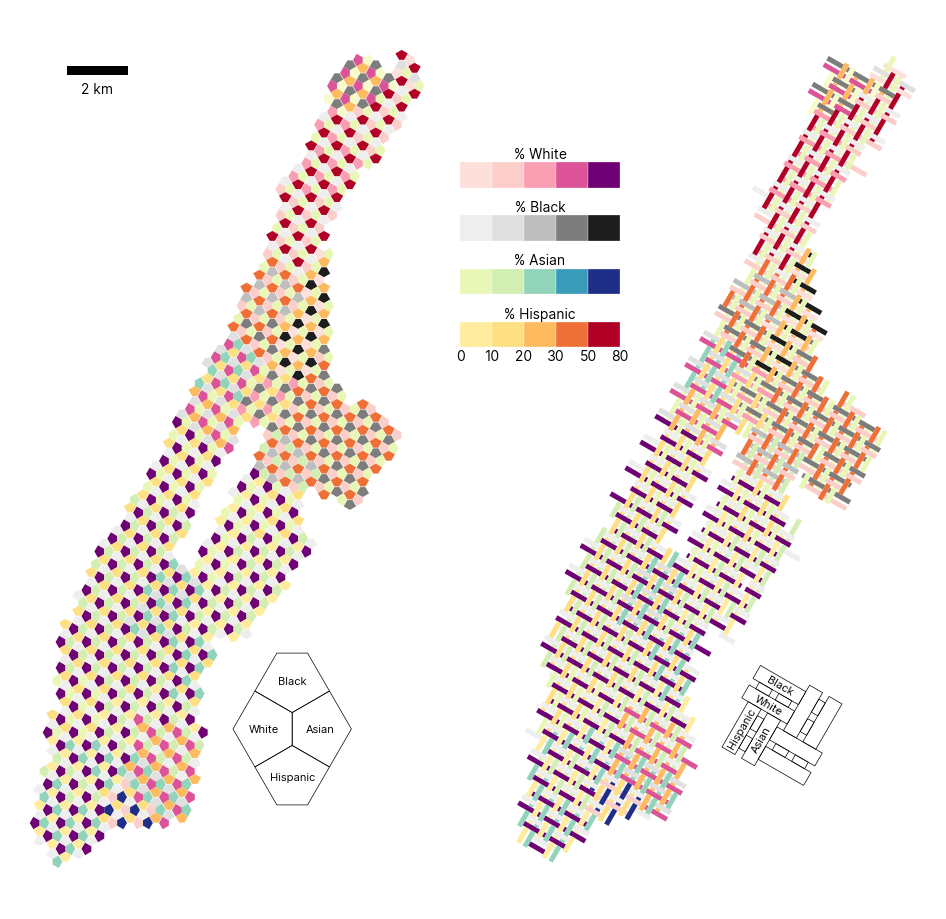

In [ ]:
fig = pyplot.figure(
  figsize = (10, 9),
  layout = "constrained"
)
panels = fig.subplot_mosaic("AB",
  width_ratios = (1, 1), # (1, 1, 2, 2),
  height_ratios = (1, ) #(1, 1)
)
cmaps = [
  LinearSegmentedColormap.from_list("white", colormaps["RdPu"]([0.05, 0.15, 0.25, 0.5, 0.9])), 
  LinearSegmentedColormap.from_list("black", colormaps["Greys"]([0.05, 0.15, 0.25, 0.5, 0.9])), 
  LinearSegmentedColormap.from_list("asian", colormaps["YlGnBu"]([0.05, 0.15, 0.25, 0.5, 0.9])), 
  LinearSegmentedColormap.from_list("hispanic", colormaps["YlOrRd"]([0.05, 0.15, 0.25, 0.5, 0.9]))
]
columns = ["Percent_White", "Percent_Black", "Percent_Asian", "Percent_Hispanic"]
labels = [c.replace("Percent_", "") for c in columns]
breaks = [0, 10, 20, 30, 50, 80]
mid_points = [(a + b) / 2 for a, b in zip(breaks[:-1], breaks[1:])]
key_width = 1000
key_height = 800
colour_key = gpd.GeoDataFrame(
  data = {"x": mid_points},
  geometry = gpd.GeoSeries(
    [affine.scale(
      affine.translate(tiling_utils.get_regular_polygon(key_width, 4), dx), 1, key_height / key_width)
     for dx in [key_width * i for i in range(len(mid_points))]]),
  crs = 3857)

for panel, tiling in zip(list("AB"), [tiling2, tiling3]):
  ax = panels[panel]
  ax.set_axis_off()
  tiled_map = tiling.get_tiled_map()
  my_map = tiled_map.map
  for tile_id, column, cmap in zip(list("abcd"), columns, cmaps):
    my_map[my_map.tile_id == tile_id].plot(ax = ax, column = column, cmap = cmap,
                                           scheme = "UserDefined", classification_kwds = {"bins": breaks})
  # manhattan.plot(ax = ax, fc = "#ffffff00", ec = "k", lw = 0.5)
  legend_ax = ax.inset_axes([0.5, 0.05, 0.3, 0.3])
  tile_unit = tiling.tileable.tiles
  label_tiles = tiling.tileable._get_legend_tiles()
  centres = [xy for xy in zip(label_tiles.geometry.centroid.x, label_tiles.geometry.centroid.y)]
  tile_unit.plot(ax = legend_ax, fc = "#ffffff00", ec = "k", lw = 0.5)
  for label, xy, rotation in zip(labels, centres, [0, 0, 0, 0] if panel == "A" else [-30, -30, 60, 60]):
    legend_ax.annotate(label, xy = xy, rotation = rotation, ha = "center", va = "center", fontsize = 8)
  legend_ax.set_axis_off()
  if panel == "A":
    ax.add_artist(ScaleBar(dx = 1, location = "upper left", pad = 4))
    # ax.add_artist(NorthArrow(location = "upper center", scale = 0.3, shadow = False, fancy = False,
    #               rotation = dict(degrees = 0), aob = dict(pad = 3)))
  if panel == "B":
    for j, (dy, cmap, column) in enumerate(zip([0.06 * j for j in range(4)], cmaps, columns)):
      cbax = ax.inset_axes(bounds = [-0.1, 0.8 - dy, 0.4, 0.04])
      cbax.set_axis_off()
      colour_key.plot(ax = cbax, column = "x", cmap = cmap, ec = "w", lw = 0.2,
                      scheme = "UserDefined", classification_kwds = {"bins": breaks})
      # mappable = cm.ScalarMappable(norm = mcolors.Normalize(0, 100), cmap = cmap)
      # cbar = fig.colorbar(mappable, cax = cbax, orientation = "horizontal")
      cbax.set_title(column.replace("Percent_", "% "), ha = "center", va = "top", fontsize = 10)
      if j == 3:
        for k, x in enumerate(breaks):
          cbax.annotate(x, xy = (k * key_width - key_width / 2, -key_height / 2 - 40), 
          xycoords = "data", ha = "center", va = "top")

fig.get_layout_engine().set(wspace = 0.01, hspace = 0.01, w_pad = 0.0, h_pad = 0.0)
fig.get_layout_engine()._compress = True

# pyplot.savefig("fig-16-nyc-acs-2024.svg")

### Figure 17 Categorical data

/Users/david/Documents/research/Papers/tilings-and-woven-patterns-for-multivariate-mapping/.venv/lib/python3.12/site-packages/shapely/constructive.py:1353: RuntimeWarning: invalid value encountered in oriented_envelope
  return lib.oriented_envelope(geometry, **kwargs)


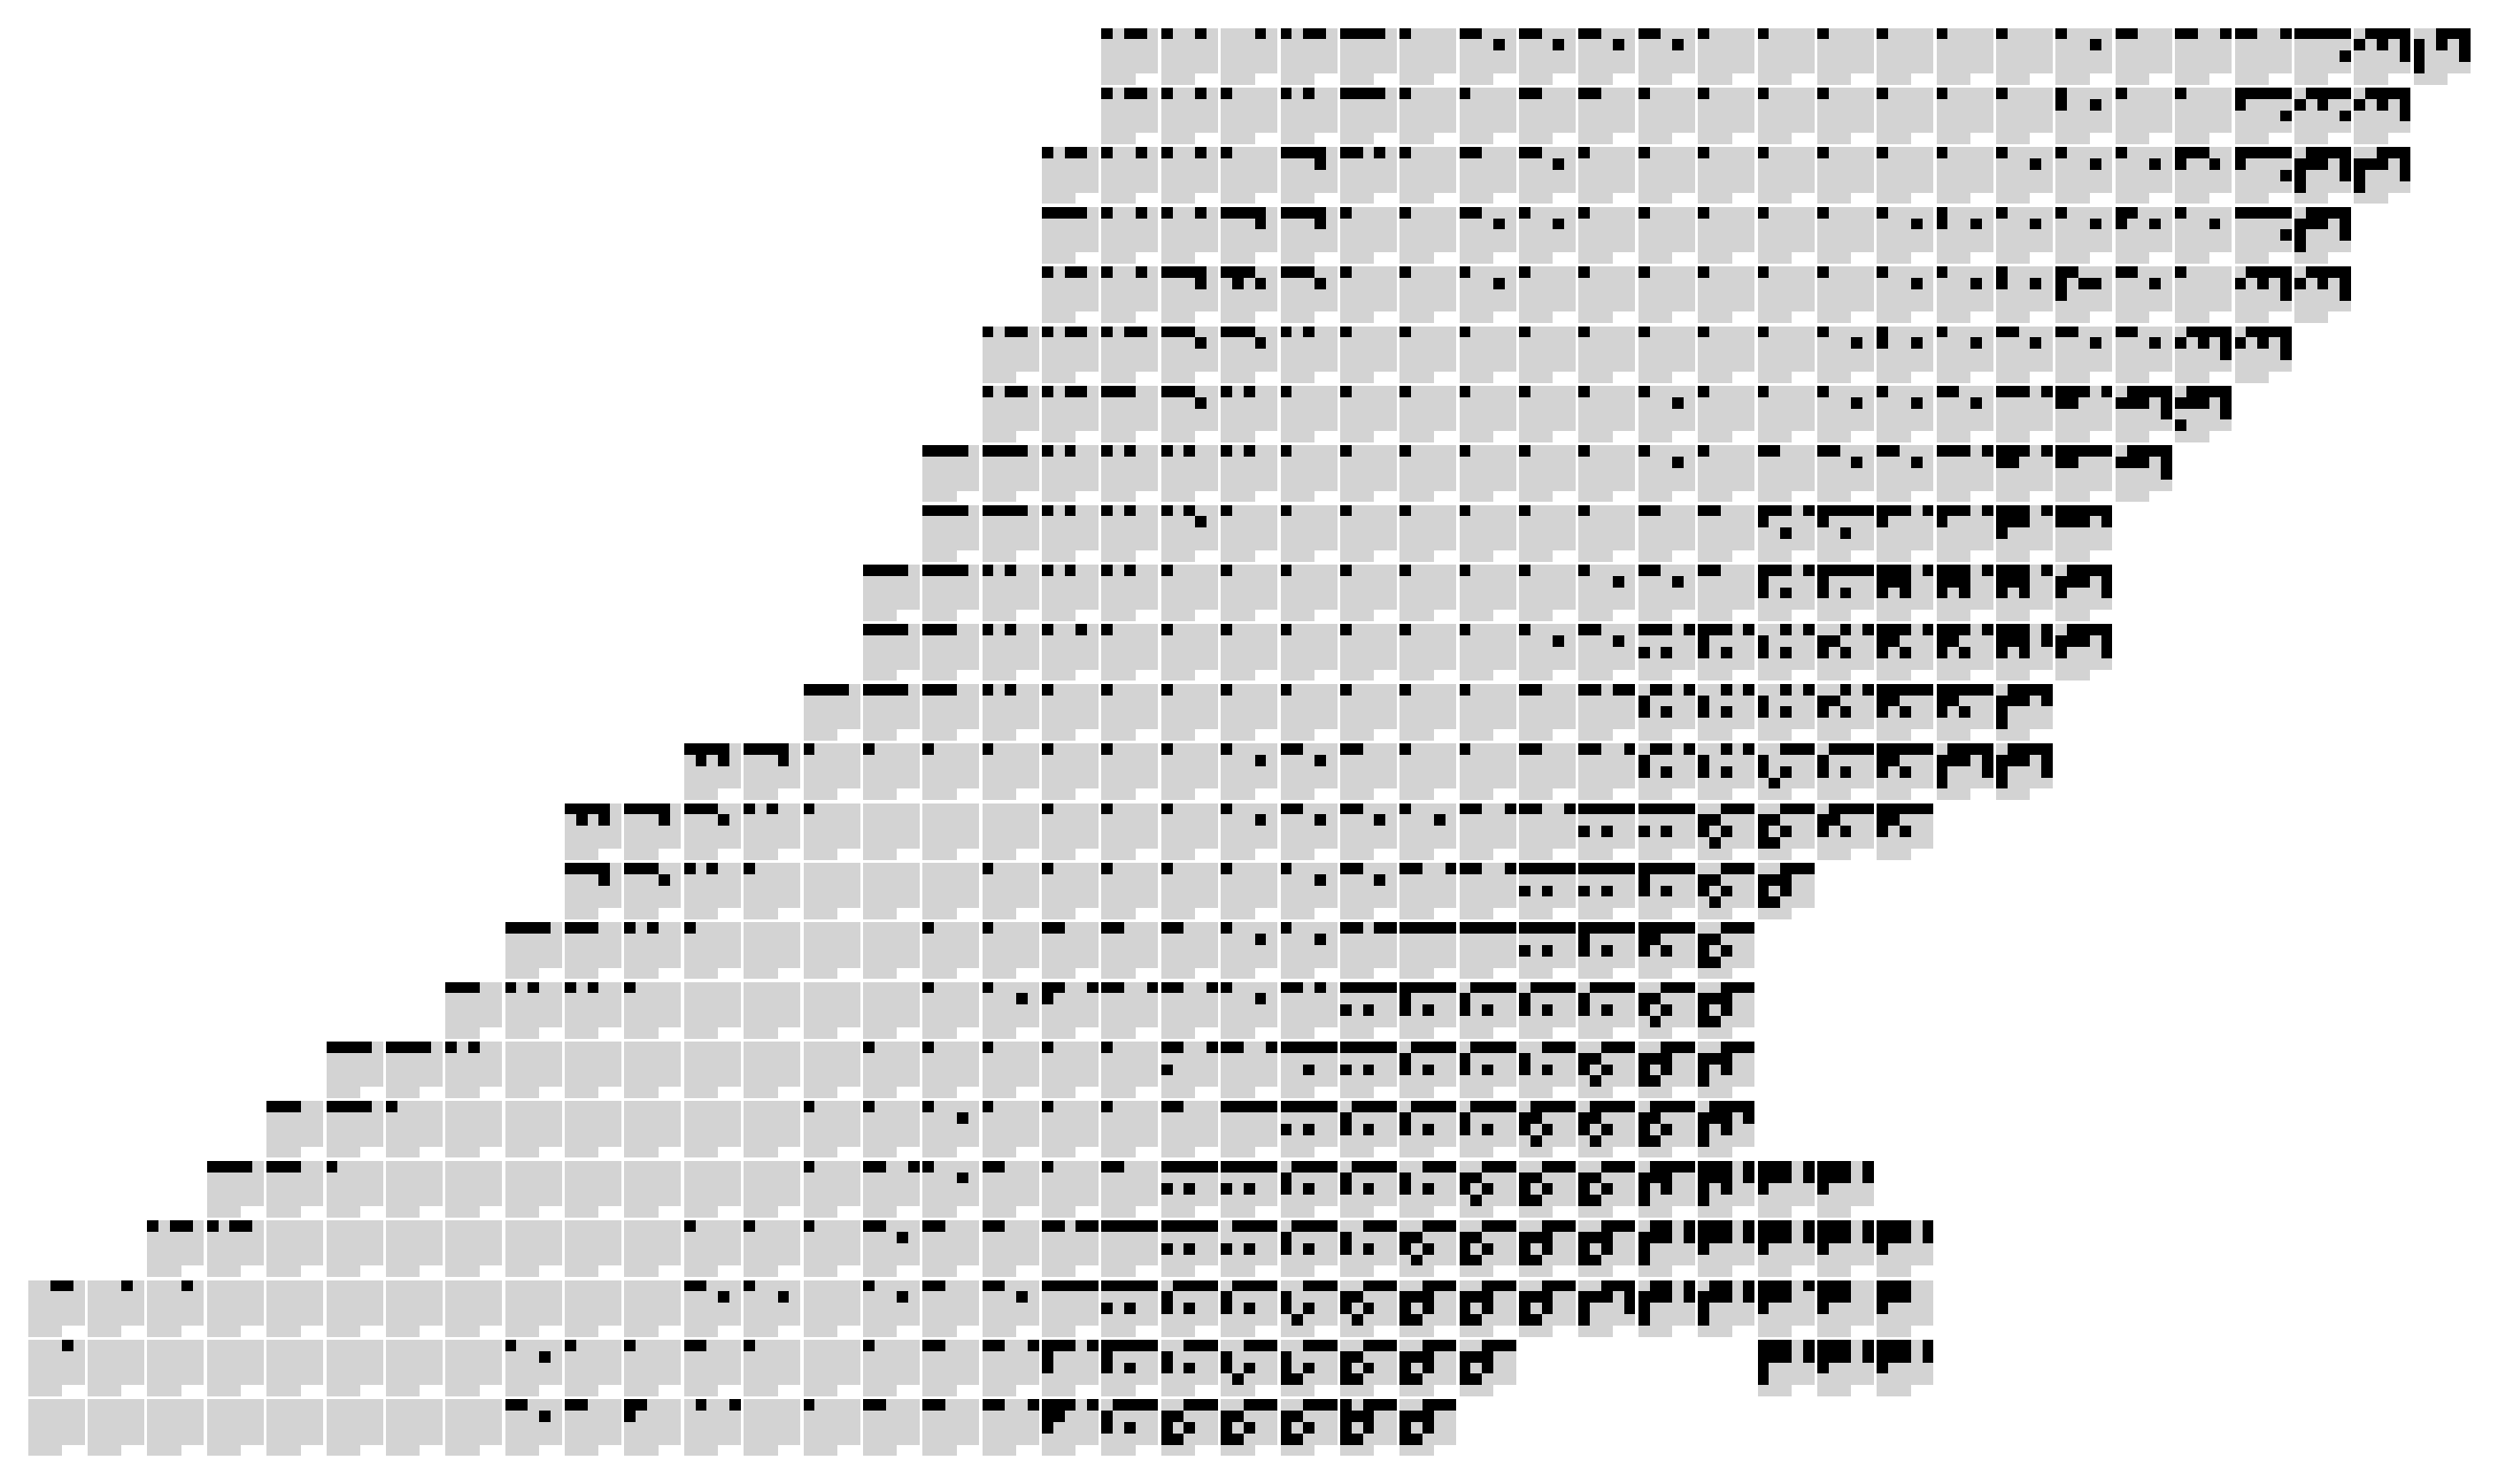

In [27]:
d2 = gpd.read_file("data/23-mosquitos.gpkg")
t = TileUnit(
    tiling_type = "grid", n = 23, nrows = 5, ncols = 5, spacing = 10000, 
    crs = d2.crs).transform_scale(0.95, 0.95, independent_of_tiling = True)
tiling = Tiling(t, d2)
sample_tile = tiling.prototiles.geometry[0]
pt = tiling_utils.get_corners(sample_tile)[0].coords[0]
x, y = pt
dx, dy = 9000 - x % 10000, 7000 - y % 10000
tiling.prototiles.geometry = gpd.GeoSeries(
    [affine.translate(p, dx, dy) for p in tiling.prototiles.geometry])
tiling.tiles.geometry = gpd.GeoSeries(
    [affine.translate(p, dx, dy) for p in tiling.tiles.geometry])
tm = tiling.get_tiled_map(
  join_on_prototiles = False,
  rotation = 0)

ids = list("abcdefghijklmnopqrstuvw")
map = tm.map[tm.map.tile_id.isin(ids)]
vars = list(map.iloc[:, 3:26]
    .sum(axis = "index")
    .sort_values(ascending = False)
    .index)
fig = pyplot.figure(figsize = (12, 7), dpi = 300)
ax = fig.add_subplot(111)
cmap = ListedColormap(["lightgray", "black"], N = 2)
layers = map.groupby("tile_id")
for id, var in zip(ids, vars):
    layer = layers.get_group(id)
    layer.plot(ax = ax, lw = 0, column = var, scheme = None, 
               categories = [0, 1], cmap = cmap)
ax.set_xlim(1.289e6, 1.699e6)
ax.set_ylim(5.127e6, 5.367e6)
ax.set_axis_off()

# pyplot.savefig("fig-17-23-mosquitoes.svg")